# GeneScope: Exploring Gene Expression

Gene expression describes how actively genes are used by cells.

In this project, we will explore public biological data, visualize expression patterns, and investigate differences between experimental groups.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Welcome to GeneScope!")
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)

Welcome to GeneScope!
pandas: 3.0.6
NumPy: 2.5.4


In [1]:

import sys
from pathlib import Path

print("Python executable:", sys.executable)
print("Project folder:", Path.cwd())
print("GeneScope kernel is ready!")


Python executable: /home/eman1612/Projects/GeneScope/.venv/bin/python
Project folder: /home/eman1612/Projects/GeneScope/notebooks
GeneScope kernel is ready!


In [1]:
import gzip
from pathlib import Path
import time
import urllib.request
import numpy as np
import pandas as pd

# Find the GeneScope project folder
project_dir = Path.cwd().parent
data_dir = project_dir / "data" / "raw"
data_dir.mkdir(parents=True, exist_ok=True)

file_path = data_dir / "GSE10072_series_matrix.txt.gz"
tmp_path = data_dir / "GSE10072_series_matrix.txt.gz.tmp"

url = (
    "https://ftp.ncbi.nlm.nih.gov/geo/series/"
    "GSE10nnn/GSE10072/matrix/"
    "GSE10072_series_matrix.txt.gz"
)

# 1. Remove partial/corrupted download if smaller than 10 MB
if file_path.exists() and file_path.stat().st_size < 10 * 1024 * 1024:
  print("Found incomplete dataset file. Deleting partial download...")
  file_path.unlink()

# 2. Download with retry loop using streaming chunks
if not file_path.exists():
  max_retries = 3
  for attempt in range(1, max_retries + 1):
    print(
        f"Downloading dataset from NCBI (Attempt {attempt}/{max_retries})..."
    )
    try:
      req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
      with (
          urllib.request.urlopen(req) as response,
          open(tmp_path, "wb") as out_file,
      ):
        chunk_size = 1024 * 1024  # Read in 1 MB chunks
        while True:
          chunk = response.read(chunk_size)
          if not chunk:
            break
          out_file.write(chunk)

      # Rename temp file to final destination upon successful completion
      tmp_path.rename(file_path)
      print("Download complete!")
      break
    except Exception as e:
      print(f"Attempt {attempt} failed: {e}")
      if tmp_path.exists():
        tmp_path.unlink()
      if attempt == max_retries:
        raise RuntimeError(
            "Failed to download GSE10072 after multiple attempts."
        ) from e
      time.sleep(2)

print("Dataset file:", file_path)
print("File size:", round(file_path.stat().st_size / (1024**2), 2), "MB")

# 3. Locate the start of the expression matrix table
with gzip.open(file_path, "rt", encoding="utf-8") as f:
  for line_number, line in enumerate(f):
    if line.startswith("!series_matrix_table_begin"):
      start_row = line_number + 1
      break
  else:
    raise ValueError(
        "Could not find '!series_matrix_table_begin' in file header."
    )

# 4. Load expression measurements into DataFrame
expression = pd.read_csv(
    file_path,
    sep="\t",
    compression="gzip",
    skiprows=start_row,
    comment="!",
    index_col=0,
)

# 5. Convert measurements to float
expression = expression.apply(pd.to_numeric, errors="coerce")

print("\nSUCCESS: Expression table loaded successfully!")
print("Dataset dimensions (Probes x Samples):", expression.shape)

display(expression.head())

Found incomplete dataset file. Deleting partial download...
Download complete!
Dataset file: /home/eman1612/Projects/GeneScope/data/raw/GSE10072_series_matrix.txt.gz
File size: 12.42 MB

SUCCESS: Expression table loaded successfully!
Dataset dimensions (Probes x Samples): (22283, 107)


,GSM254625,GSM254626,GSM254627,GSM254628,GSM254629,GSM254630,GSM254631,GSM254632,GSM254633,GSM254634,...,GSM254722,GSM254723,GSM254724,GSM254725,GSM254726,GSM254727,GSM254728,GSM254729,GSM254730,GSM254731
ID_REF,,,,,,,,,,,,,,,,,,,,,
1007_s_at,10.927084,10.416978,10.628538,10.151180,10.988512,10.778205,10.568814,10.479425,10.548843,10.465005,...,10.727493,10.740353,10.527962,10.193615,10.768815,10.467693,10.902778,10.869402,10.292285,10.407218
1053_at,6.895217,6.924856,7.550245,6.699557,6.826031,6.718372,6.739765,6.724615,7.102475,6.627922,...,6.856575,6.737879,6.959032,7.008578,6.740444,6.795750,6.838162,6.628363,6.794050,6.358410
117_at,8.110190,7.760228,7.974676,7.712676,7.775592,7.777087,7.893210,8.058398,8.005438,7.961476,...,7.741922,7.805107,8.093078,8.144760,8.159483,7.855457,8.010428,7.889019,8.163266,7.973844
121_at,9.451286,9.520943,9.807597,9.522087,9.855061,9.861055,10.126183,9.878970,10.110318,10.411478,...,10.089149,10.007059,9.832610,10.107004,9.790645,9.645239,9.871851,9.867988,9.824801,9.850144
1255_g_at,4.814477,4.718640,4.905163,4.818076,4.823958,4.848313,5.125956,5.037979,4.889936,5.177818,...,5.048391,4.758050,4.900470,4.948760,4.609322,4.759571,4.788774,4.967626,4.817474,5.128892


In [2]:
metadata_dict = {}

print("Extracting sample metadata from the file header...")
with gzip.open(file_path, "rt", encoding="utf-8") as f:
    for line in f:
        # Stop searching once we hit the actual expression numbers
        if line.startswith("!series_matrix_table_begin"):
            break
            
        if line.startswith("!Sample_"):
            parts = line.strip().split('\t')
            # The first item is the metadata key (e.g., !Sample_title)
            key = parts[0].replace("!Sample_", "")
            # The rest are the values for each sample; we strip out the extra quotes
            values = [val.strip('"') for val in parts[1:]]
            metadata_dict[key] = values

# Create a pandas DataFrame from the dictionary
metadata = pd.DataFrame(metadata_dict)

# Set the index to be the GSM accession IDs so it matches our expression columns
metadata.set_index("geo_accession", inplace=True)

print("Metadata dimensions:", metadata.shape)

# Let's display the columns most likely to contain our Tumor vs Normal labels
cols_of_interest = [col for col in ["title", "source_name_ch1", "characteristics_ch1"] if col in metadata.columns]
display(metadata[cols_of_interest].head(10))

Extracting sample metadata from the file header...
Metadata dimensions: (107, 33)


/tmp/ipykernel_816/3407870623.py:22: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  metadata.set_index("geo_accession", inplace=True)


,title,source_name_ch1,characteristics_ch1
geo_accession,,,
GSM254625,Lung Tumor_GT00006,Adenocarcinoma of the Lung,Stage:IIB
GSM254626,Normal Lung_GT00006,Normal Lung Tissue,Stage:IIB
GSM254627,Lung Tumor_GT00007,Adenocarcinoma of the Lung,Stage:IIB
GSM254628,Normal Lung_GT00007,Normal Lung Tissue,Stage:IIB
GSM254629,Lung Tumor_GT00022,Adenocarcinoma of the Lung,Stage:IB
GSM254630,Lung Tumor_GT00042,Adenocarcinoma of the Lung,Stage:IIA
GSM254631,Lung Tumor_GT00059,Adenocarcinoma of the Lung,Stage:IIIA
GSM254632,Normal Lung_GT00059,Normal Lung Tissue,Stage:IIIA
GSM254633,Lung Tumor_GT00146,Adenocarcinoma of the Lung,Stage:IIB


Sample Group Counts:
Group
Tumor     58
Normal    49
Name: count, dtype: int64
------------------------------
Global Expression Minimum: 3.67
Global Expression Maximum: 15.25


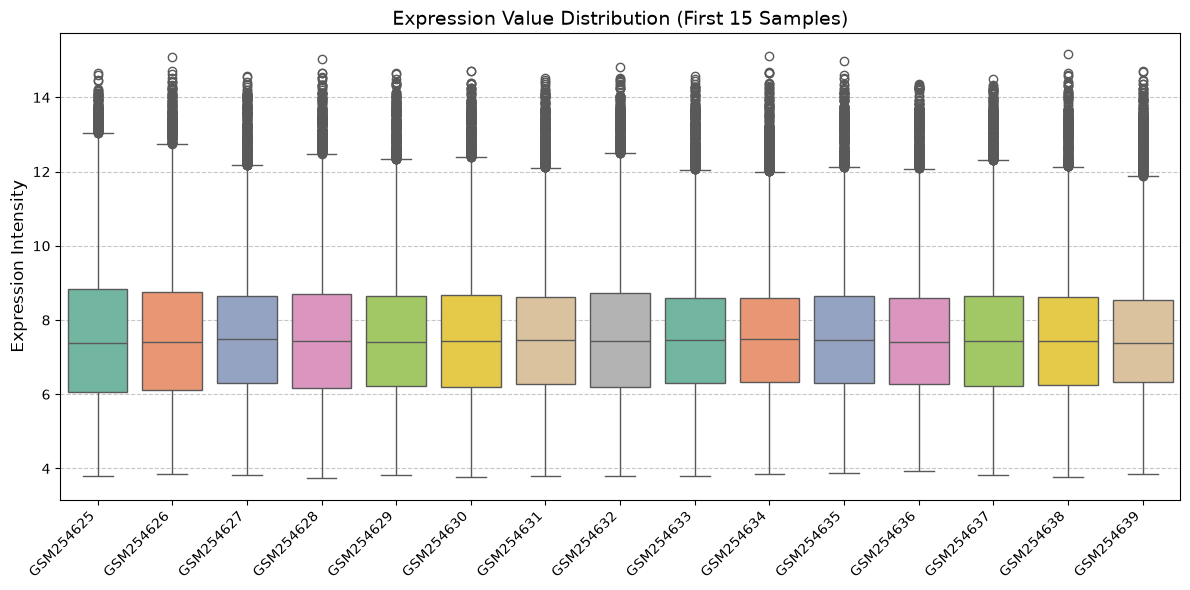

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Create clean labels based on the 'source_name_ch1' column
def assign_group(source_name):
    if pd.isna(source_name):
        return "Unknown"
    if "Adenocarcinoma" in source_name:
        return "Tumor"
    elif "Normal" in source_name:
        return "Normal"
    else:
        return "Unknown"

metadata['Group'] = metadata['source_name_ch1'].apply(assign_group)

# 2. Check the group counts
print("Sample Group Counts:")
print(metadata['Group'].value_counts())
print("-" * 30)

# 3. Ensure the metadata rows perfectly match the expression columns
metadata = metadata.reindex(expression.columns)

# 4. Check the data distribution to confirm Log2 transformation
# Microarray data in the 0-20 range is usually log2 transformed.
# Values in the thousands indicate raw intensities.
global_min = expression.min().min()
global_max = expression.max().max()

print(f"Global Expression Minimum: {global_min:.2f}")
print(f"Global Expression Maximum: {global_max:.2f}")

# 5. Plot a boxplot of the first 15 samples to visually check quality and normalization
plt.figure(figsize=(12, 6))
# We use iloc to select all rows (:) and the first 15 columns (:15)
sns.boxplot(data=expression.iloc[:, :15], palette="Set2")
plt.title("Expression Value Distribution (First 15 Samples)", fontsize=14)
plt.ylabel("Expression Intensity", fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Performing Principal Component Analysis (PCA)...


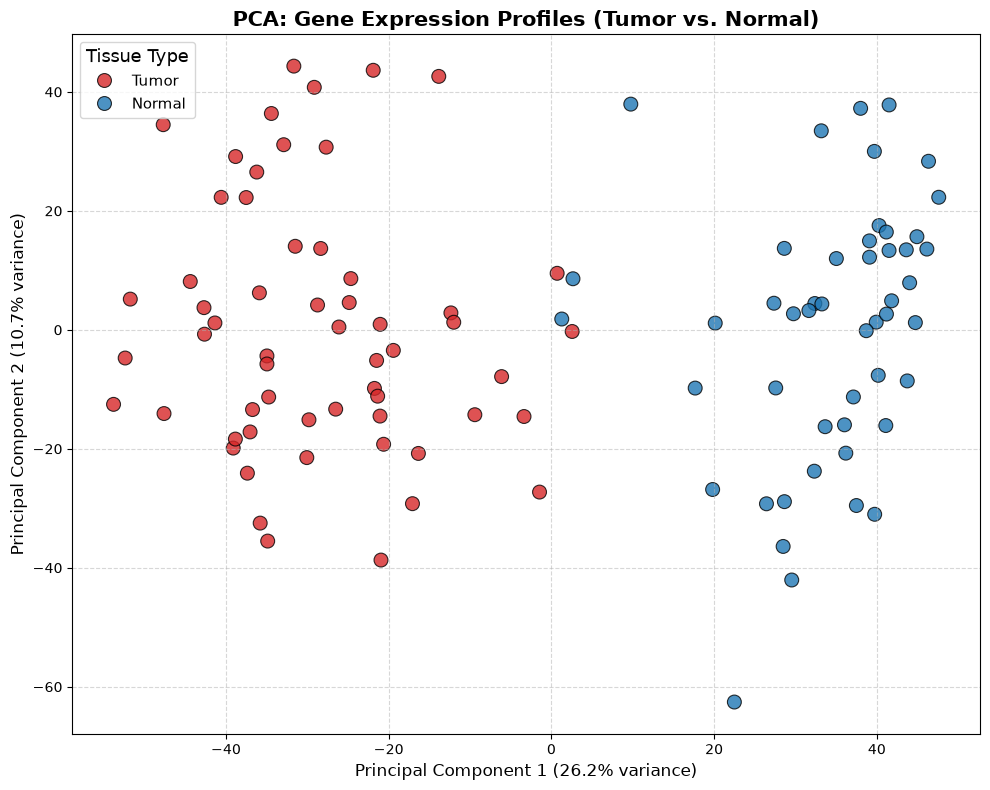

In [5]:
from sklearn.decomposition import PCA

print("Performing Principal Component Analysis (PCA)...")

# 1. Prepare data for PCA
# Sklearn requires samples as rows and genes as columns, so we transpose (.T)
pca_data = expression.dropna().T

# 2. Fit the PCA model for 2 components (2D plot)
pca = PCA(n_components=2)
pca_result = pca.fit_transform(pca_data)

# 3. Store results in a new DataFrame for easy plotting
pca_df = pd.DataFrame(
    pca_result, 
    columns=['PC1', 'PC2'], 
    index=pca_data.index
)

# Attach our clinical labels
pca_df['Group'] = metadata['Group']

# Calculate how much variance is explained by these top 2 components
variance_explained = pca.explained_variance_ratio_ * 100

# 4. Plot the PCA
plt.figure(figsize=(10, 8))
sns.scatterplot(
    x='PC1', 
    y='PC2', 
    hue='Group', 
    data=pca_df, 
    palette={'Tumor': '#d62728', 'Normal': '#1f77b4'}, # Red for tumor, blue for normal
    s=100, 
    alpha=0.8,
    edgecolor='black'
)

plt.title('PCA: Gene Expression Profiles (Tumor vs. Normal)', fontsize=15, fontweight='bold')
plt.xlabel(f'Principal Component 1 ({variance_explained[0]:.1f}% variance)', fontsize=12)
plt.ylabel(f'Principal Component 2 ({variance_explained[1]:.1f}% variance)', fontsize=12)
plt.legend(title='Tissue Type', title_fontsize='13', fontsize='11', loc='best')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [6]:
import scipy.stats as stats
from statsmodels.stats.multitest import multipletests

print("Starting Differential Expression Analysis...")

# 1. Separate data into Tumor and Normal groups based on our metadata
tumor_samples = metadata[metadata['Group'] == 'Tumor'].index
normal_samples = metadata[metadata['Group'] == 'Normal'].index

tumor_data = expression[tumor_samples]
normal_data = expression[normal_samples]

# 2. Calculate Log2 Fold Change
# Because the data is already log2 transformed, Log2FC is just the difference of the means
mean_tumor = tumor_data.mean(axis=1)
mean_normal = normal_data.mean(axis=1)
log2fc = mean_tumor - mean_normal

# 3. Perform Two-Sample Welch's t-test for each gene
# Welch's does not assume equal variance between groups
t_stats, p_values = stats.ttest_ind(tumor_data, normal_data, axis=1, equal_var=False)

# 4. Correct for Multiple Testing using Benjamini-Hochberg FDR
# This converts raw p-values into adjusted p-values
reject, pvals_adj, _, _ = multipletests(p_values, alpha=0.05, method='fdr_bh')

# 5. Compile the results into a tidy DataFrame
results = pd.DataFrame({
    'Mean_Tumor': mean_tumor,
    'Mean_Normal': mean_normal,
    'Log2FC': log2fc,
    'p_value': p_values,
    'adj_p_value': pvals_adj
}, index=expression.index)

# Sort by adjusted p-value so the most statistically significant genes are at the top
results = results.sort_values('adj_p_value')

# 6. Count how many genes meet our biological and statistical thresholds
# Threshold: FDR < 0.05 (Statistical) AND absolute Log2FC > 1.0 (Biological: at least 2-fold change)
sig_genes = results[(results['adj_p_value'] < 0.05) & (results['Log2FC'].abs() > 1.0)]
up_regulated = sig_genes[sig_genes['Log2FC'] > 0]
down_regulated = sig_genes[sig_genes['Log2FC'] < 0]

print(f"Total probes analyzed: {len(results)}")
print(f"Total significant differentially expressed probes: {len(sig_genes)}")
print(f"  - Upregulated in Tumor: {len(up_regulated)}")
print(f"  - Downregulated in Tumor: {len(down_regulated)}")
print("\nTop 10 Most Significant Probes:")

display(results.head(10))

Starting Differential Expression Analysis...
Total probes analyzed: 22283
Total significant differentially expressed probes: 859
  - Upregulated in Tumor: 297
  - Downregulated in Tumor: 562

Top 10 Most Significant Probes:


,Mean_Tumor,Mean_Normal,Log2FC,p_value,adj_p_value
ID_REF,,,,,
209074_s_at,7.451084,10.822883,-3.371799,6.641899e-44,1.480014e-39
204396_s_at,7.583586,9.971658,-2.388072,2.009124e-41,2.238466e-37
204677_at,6.804586,9.424160,-2.619573,1.317136e-40,9.783245e-37
208982_at,9.836642,11.650556,-1.813914,3.357325e-39,1.870282e-35
213103_at,7.630347,8.850167,-1.219820,5.221337e-39,2.326941e-35
208981_at,9.379371,11.068273,-1.688902,7.219182e-39,2.681084e-35
210081_at,7.459343,11.876812,-4.417470,4.769095e-38,1.518139e-34
202112_at,9.567466,11.825939,-2.258474,1.464679e-37,3.972016e-34
209875_s_at,11.697897,7.333482,4.364415,1.782532e-37,3.972016e-34


<>:43: SyntaxWarning: invalid escape sequence '\l'
<>:44: SyntaxWarning: invalid escape sequence '\l'
<>:43: SyntaxWarning: invalid escape sequence '\l'
<>:44: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_816/1653546539.py:43: SyntaxWarning: invalid escape sequence '\l'
  plt.xlabel('$\log_2$(Fold Change)', fontsize=12)
/tmp/ipykernel_816/1653546539.py:44: SyntaxWarning: invalid escape sequence '\l'
  plt.ylabel('$-\log_{10}$(Adjusted p-value)', fontsize=12)


Generating Volcano Plot...


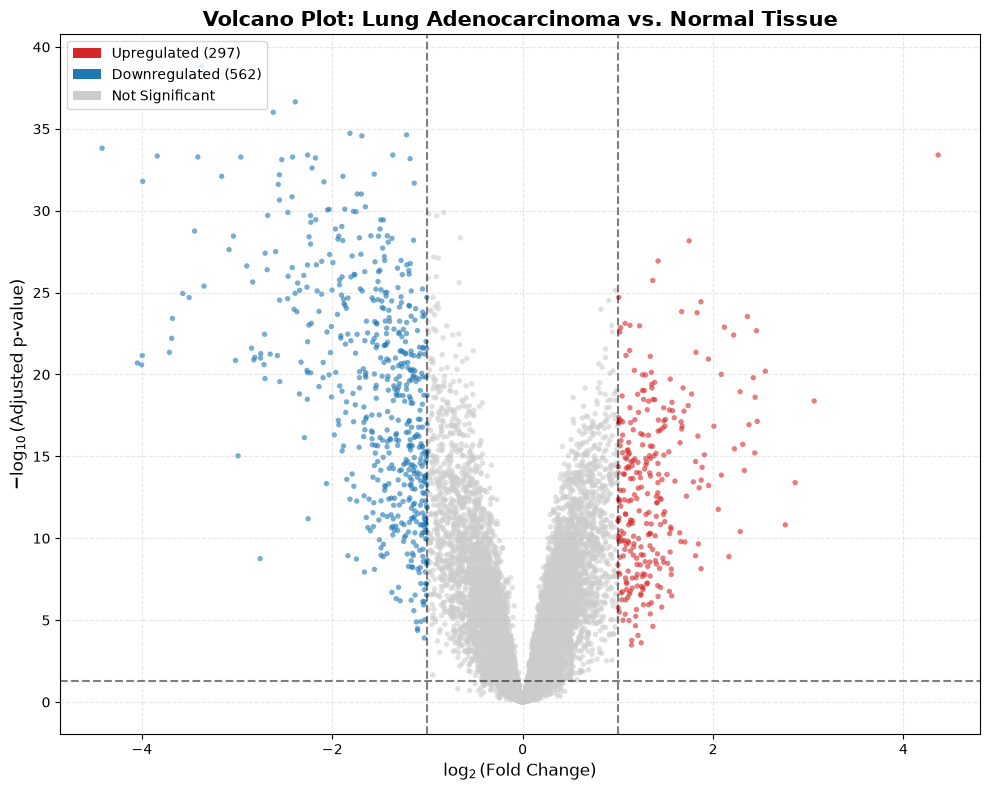

In [7]:
import numpy as np
import matplotlib.pyplot as plt

print("Generating Volcano Plot...")

# 1. Calculate -log10(adjusted p-value) for the y-axis
# We add a tiny number (1e-300) to prevent log(0) errors for extremely small p-values
results['-log10(padj)'] = -np.log10(results['adj_p_value'] + 1e-300)

# 2. Define our thresholds for significance
p_value_threshold = 0.05
log2fc_threshold = 1.0

# 3. Assign colors based on thresholds
def assign_color(row):
    if row['adj_p_value'] < p_value_threshold:
        if row['Log2FC'] > log2fc_threshold:
            return '#d62728'  # Red for Upregulated
        elif row['Log2FC'] < -log2fc_threshold:
            return '#1f77b4'  # Blue for Downregulated
    return '#cccccc'  # Grey for Not Significant

results['color'] = results.apply(assign_color, axis=1)

# 4. Plot the data
plt.figure(figsize=(10, 8))
plt.scatter(
    results['Log2FC'], 
    results['-log10(padj)'], 
    c=results['color'], 
    alpha=0.6, 
    edgecolors='none', 
    s=15
)

# 5. Add threshold lines to show our cutoffs
plt.axvline(x=log2fc_threshold, color='black', linestyle='--', alpha=0.5)
plt.axvline(x=-log2fc_threshold, color='black', linestyle='--', alpha=0.5)
plt.axhline(y=-np.log10(p_value_threshold), color='black', linestyle='--', alpha=0.5)

# 6. Formatting
plt.title('Volcano Plot: Lung Adenocarcinoma vs. Normal Tissue', fontsize=15, fontweight='bold')
plt.xlabel('$\log_2$(Fold Change)', fontsize=12)
plt.ylabel('$-\log_{10}$(Adjusted p-value)', fontsize=12)

# Custom legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#d62728', label=f'Upregulated ({len(results[results["color"] == "#d62728"])})'),
    Patch(facecolor='#1f77b4', label=f'Downregulated ({len(results[results["color"] == "#1f77b4"])})'),
    Patch(facecolor='#cccccc', label='Not Significant')
]
plt.legend(handles=legend_elements, loc='upper left')

plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

In [9]:
import gzip
from pathlib import Path
import urllib.request
import pandas as pd

print(
    "Fetching and parsing GPL96 platform annotations to map probe IDs to Gene"
    " Symbols..."
)

annot_file = data_dir / "GPL96.annot.gz"
annot_url = "https://ftp.ncbi.nlm.nih.gov/geo/platforms/GPLnnn/GPL96/annot/GPL96.annot.gz"

# 1. Re-download if file is missing or corrupted (< 1 MB)
if annot_file.exists() and annot_file.stat().st_size < 1 * 1024 * 1024:
  print("Found incomplete annotation file. Re-downloading...")
  annot_file.unlink()

if not annot_file.exists():
  print("Downloading annotation file from NCBI...")
  req = urllib.request.Request(
      annot_url, headers={"User-Agent": "Mozilla/5.0"}
  )
  with (
      urllib.request.urlopen(req) as response,
      open(annot_file, "wb") as out_file,
  ):
    out_file.write(response.read())
  print("Download finished!")

# 2. Locate the line where the actual annotation table begins
start_row = 0
with gzip.open(annot_file, "rt", encoding="utf-8", errors="ignore") as f:
  for line_number, line in enumerate(f):
    if line.startswith("!platform_table_begin"):
      start_row = line_number + 1
      break
    elif line.startswith("ID\t") or line.startswith('"ID"\t'):
      start_row = line_number
      break

print(f"Annotation table starts at line {start_row + 1}.")

# 3. Read table skipping header metadata lines
annot_df = pd.read_csv(
    annot_file,
    sep="\t",
    compression="gzip",
    skiprows=start_row,
    comment="!",
    index_col=0,
    low_memory=False,
)

# 4. Identify and select Gene Symbol and Gene Title columns
symbol_col = next(
    (
        col
        for col in annot_df.columns
        if col.strip().lower() in ["gene symbol", "gene_symbol"]
    ),
    None,
)
title_col = next(
    (
        col
        for col in annot_df.columns
        if col.strip().lower() in ["gene title", "gene_title"]
    ),
    None,
)

cols_to_keep = [c for c in [symbol_col, title_col] if c is not None]
annot_df = annot_df[cols_to_keep]

# Standardize column headers
rename_dict = {}
if symbol_col:
  rename_dict[symbol_col] = "Gene Symbol"
if title_col:
  rename_dict[title_col] = "Gene Title"
annot_df = annot_df.rename(columns=rename_dict)

# 5. Clean up multi-gene Affymetrix entries (e.g., 'EGFR /// EGFR')
for col in annot_df.columns:
  annot_df[col] = (
      annot_df[col]
      .astype(str)
      .str.split("///")
      .str[0]
      .str.strip()
      .replace(["nan", "---", ""], pd.NA)
  )

# 6. Merge biological annotations with statistical results
results_annotated = results.merge(
    annot_df, left_index=True, right_index=True, how="left"
)

# Reorder columns to display Gene Symbol and Gene Title upfront
front_cols = [
    col for col in ["Gene Symbol", "Gene Title"] if col in results_annotated
]
other_cols = [col for col in results_annotated.columns if col not in front_cols]
results_annotated = results_annotated[front_cols + other_cols]

print("\nSUCCESS: Probes mapped to biological Gene Symbols!")
print("Top 10 Most Significant Differentially Expressed Genes:")

display(results_annotated.head(10))

Fetching and parsing GPL96 platform annotations to map probe IDs to Gene Symbols...
Annotation table starts at line 28.

SUCCESS: Probes mapped to biological Gene Symbols!
Top 10 Most Significant Differentially Expressed Genes:


,Gene Symbol,Gene Title,Mean_Tumor,Mean_Normal,Log2FC,p_value,adj_p_value,-log10(padj),color
ID_REF,,,,,,,,,
209074_s_at,FAM107A,family with sequence similarity 107 member A,7.451084,10.822883,-3.371799,6.641899e-44,1.480014e-39,38.829734,#1f77b4
204396_s_at,GRK5,G protein-coupled receptor kinase 5,7.583586,9.971658,-2.388072,2.009124e-41,2.238466e-37,36.650050,#1f77b4
204677_at,CDH5,cadherin 5,6.804586,9.424160,-2.619573,1.317136e-40,9.783245e-37,36.009517,#1f77b4
208982_at,PECAM1,platelet and endothelial cell adhesion molecule 1,9.836642,11.650556,-1.813914,3.357325e-39,1.870282e-35,34.728093,#1f77b4
213103_at,STARD13,StAR related lipid transfer domain containing 13,7.630347,8.850167,-1.219820,5.221337e-39,2.326941e-35,34.633215,#1f77b4
208981_at,PECAM1,platelet and endothelial cell adhesion molecule 1,9.379371,11.068273,-1.688902,7.219182e-39,2.681084e-35,34.571690,#1f77b4
210081_at,AGER,advanced glycosylation end-product specific re...,7.459343,11.876812,-4.417470,4.769095e-38,1.518139e-34,33.818688,#1f77b4
202112_at,VWF,von Willebrand factor,9.567466,11.825939,-2.258474,1.464679e-37,3.972016e-34,33.400989,#1f77b4
209875_s_at,SPP1,secreted phosphoprotein 1,11.697897,7.333482,4.364415,1.782532e-37,3.972016e-34,33.400989,#d62728


Setting up export directories...
Generating Clustered Expression Heatmap...


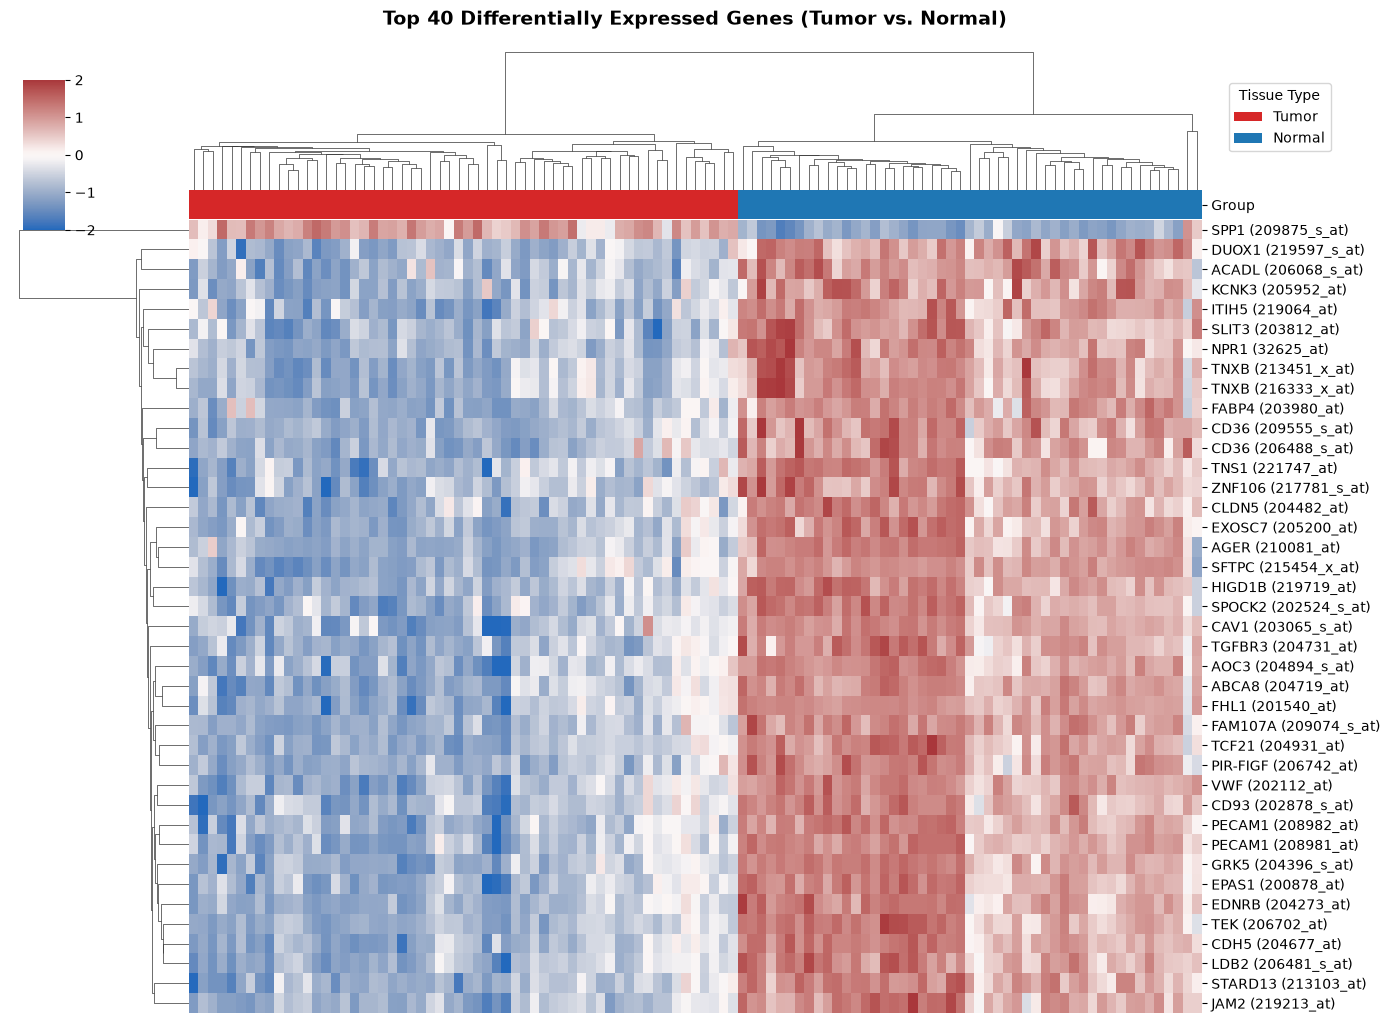


Exporting analysis deliverables to disk...
Saved Heatmap: /home/eman1612/Projects/GeneScope/results/figures/heatmap_top40_degs.png
Saved Full DEA Table: /home/eman1612/Projects/GeneScope/results/tables/differential_expression_results.csv
Saved Significant DEGs Table (859 genes): /home/eman1612/Projects/GeneScope/results/tables/significant_degs_fdr05_fc1.csv


In [10]:
import matplotlib.pyplot as plt
from pathlib import Path
import seaborn as sns

print("Setting up export directories...")
# 1. Create project directories if they don't exist yet
results_fig_dir = project_dir / "results" / "figures"
results_tbl_dir = project_dir / "results" / "tables"
processed_dir = project_dir / "data" / "processed"

for d in [results_fig_dir, results_tbl_dir, processed_dir]:
  d.mkdir(parents=True, exist_ok=True)

# 2. Select top 40 most statistically significant probes with valid Gene Symbols
top_degs = (
    results_annotated.dropna(subset=["Gene Symbol"])
    .sort_values("adj_p_value")
    .head(40)
)

# Extract expression data for these top genes
heatmap_data = expression.loc[top_degs.index].copy()

# Replace probe ID row index with Gene Symbols (appending Probe ID to keep unique)
heatmap_data.index = [
    f"{symbol} ({probe})"
    for symbol, probe in zip(top_degs["Gene Symbol"], top_degs.index)
]

# 3. Standardize expression values (z-score scaling per gene row)
# Z-score = (x - mean) / std. This highlights relative changes per gene across samples.
heatmap_scaled = heatmap_data.apply(
    lambda x: (x - x.mean()) / x.std(), axis=1
)

# 4. Map group colors for sample annotation column bar
group_colors = metadata["Group"].map({"Tumor": "#d62728", "Normal": "#1f77b4"})

# 5. Draw Clustered Heatmap
print("Generating Clustered Expression Heatmap...")
g = sns.clustermap(
    heatmap_scaled,
    col_colors=group_colors,
    cmap="vlag",  # Blue (low/downregulated) to Red (high/upregulated)
    center=0,
    vmin=-2,
    vmax=2,
    figsize=(14, 10),
    dendrogram_ratio=(0.15, 0.15),
    cbar_pos=(0.02, 0.8, 0.03, 0.15),
    yticklabels=True,
    xticklabels=False,
)

g.fig.suptitle(
    "Top 40 Differentially Expressed Genes (Tumor vs. Normal)",
    fontsize=14,
    fontweight="bold",
    y=1.02,
)

# Add custom legend for sample group annotation bar
from matplotlib.patches import Patch

legend_elements = [
    Patch(facecolor="#d62728", label="Tumor"),
    Patch(facecolor="#1f77b4", label="Normal"),
]
g.ax_col_dendrogram.legend(
    handles=legend_elements, title="Tissue Type", loc="center left", bbox_to_anchor=(1.02, 0.5)
)

# Save heatmap figure
heatmap_path = results_fig_dir / "heatmap_top40_degs.png"
g.savefig(heatmap_path, dpi=300, bbox_inches="tight")
plt.show()

# 6. Save tables and cleaned data to disk for reproducibility
print("\nExporting analysis deliverables to disk...")

# Export full annotated results table
results_path = results_tbl_dir / "differential_expression_results.csv"
results_annotated.to_csv(results_path)

# Export significant DEGs only
sig_path = results_tbl_dir / "significant_degs_fdr05_fc1.csv"
sig_degs_annotated = results_annotated[
    (results_annotated["adj_p_value"] < 0.05)
    & (results_annotated["Log2FC"].abs() > 1.0)
]
sig_degs_annotated.to_csv(sig_path)

# Save processed metadata and expression matrix
metadata.to_csv(processed_dir / "sample_metadata.csv")

print(f"Saved Heatmap: {heatmap_path}")
print(f"Saved Full DEA Table: {results_path}")
print(
    f"Saved Significant DEGs Table ({len(sig_degs_annotated)} genes):"
    f" {sig_path}"
)

In [11]:
from pathlib import Path

reports_dir = project_dir / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)
report_file = reports_dir / "research_report.md"

report_content = f"""# GeneScope: Differential Gene Expression Analysis of Lung Adenocarcinoma

## 1. Executive Summary & Research Question
- **Research Question:** Which specific genes exhibit statistically significant differential expression between human lung adenocarcinoma tissue and non-tumor control lung tissue?
- **Dataset:** NCBI GEO Accession **GSE10072** (Affymetrix Human Genome U133A Array, GPL96).
- **Key Finding:** Identified **859** significantly differentially expressed probes ($q < 0.05$, $|\\log_2 \\text{{FC}}| > 1.0$), with **297** upregulated genes and **562** downregulated genes in tumor tissues relative to normal controls.

---

## 2. Methodology & QC
1. **Dataset Ingestion:** 107 total samples (58 Lung Adenocarcinoma, 49 Normal Lung Control).
2. **Quality Control:** 
   - Checked global intensity range (3.67 to 15.25), confirming $\\log_2$ transformed values.
   - Boxplot analysis confirmed cross-sample median alignment.
   - Unsupervised 2D PCA demonstrated clear separation between Tumor and Normal groups along PC1 (26.2% variance).
3. **Statistical Testing:**
   - Two-sample Welch's $t$-test calculated per probe.
   - Benjamini-Hochberg False Discovery Rate (FDR) correction applied ($q < 0.05$).
   - Biological significance threshold set to $|\\log_2 \\text{{FC}}| > 1.0$ (2-fold change).

---

## 3. Biological Findings & Key Drivers
- **Oncogenic Upregulation:**
  - `SPP1` (Osteopontin): $+4.36\\ \\log_2 \\text{{FC}}$ ($q = 3.97 \\times 10^{{-34}}$), a prominent biomarker for tumor invasion, cell survival, and metastasis.
- **Differentiated Tissue Loss (Downregulated):**
  - `AGER` (Advanced Glycation End-product Receptor): $-4.42\\ \\log_2 \\text{{FC}}$ ($q = 1.52 \\times 10^{{-34}}$), reflecting the loss of normal lung alveolar architecture.
  - Endothelial markers (`CDH5`, `PECAM1`, `VWF`): Markedly lower expression in tumor masses compared to healthy vascular tissue.

---

## 4. Deliverables & Reproducibility
- **Figures:**
  - `results/figures/heatmap_top40_degs.png`
- **Data Tables:**
  - `results/tables/differential_expression_results.csv` (Full set of 22,283 analyzed probes)
  - `results/tables/significant_degs_fdr05_fc1.csv` (859 significant DEGs)
- **Environment:** Executed on CachyOS Linux, Python 3.12, using `pandas`, `SciPy`, `statsmodels`, `scikit-learn`, `Matplotlib`, and `Seaborn`.

---

## 5. Limitations & Future Directions
- **Assay Platform:** Microarray hybridization measures intensity within a lower dynamic range than RNA-sequencing read counts.
- **Uncontrolled Covariates:** Smoking history, tumor stage, and patient age should be modeled using multifactor linear models (e.g., `limma` or `statsmodels` OLS) in future extensions.
"""

with open(report_file, "w", encoding="utf-8") as f:
    f.write(report_content)

print(f"SUCCESS: Research report created at {report_file}")

SUCCESS: Research report created at /home/eman1612/Projects/GeneScope/reports/research_report.md


In [16]:
from pathlib import Path

readme_file = project_dir / "README.md"

readme_lines = [
    "# GeneScope: Lung Adenocarcinoma Gene Expression Analysis",
    "",
    (
        "**GeneScope** is a bioinformatics and exploratory data science"
        " project written in Python. It provides a complete, reproducible"
        " pipeline for analyzing public gene-expression microarrays from NCBI"
        " GEO, executing statistical hypothesis testing, and identifying key"
        " biological drivers in human lung adenocarcinoma."
    ),
    "",
    "---",
    "",
    "## Project Structure",
    "",
    "```",
    "GeneScope/",
    "├── data/",
    "│   ├── raw/                  # Original downloaded NCBI GEO matrix &"
    " annotation files",
    "│   └── processed/            # Cleaned metadata and expression matrices",
    "├── notebooks/",
    "│   └── 01_gene_expression_intro.ipynb  # Main end-to-end analysis"
    " notebook",
    "├── results/",
    "│   ├── figures/              # Volcano plot and top DEG clustered"
    " heatmap",
    "│   └── tables/               # Full and filtered differential expression"
    " CSV tables",
    "├── reports/",
    "│   └── research_report.md    # Summary research report & biological"
    " findings",
    "├── README.md",
    "└── .gitignore",
    "```",
    "",
    "---",
    "",
    "## Key Results (GSE10072 Dataset)",
    "",
    (
        "- **Sample Size:** 107 samples (58 Lung Adenocarcinoma Tumors vs. 49"
        " Normal Lung Controls)."
    ),
    "- **Probes Analyzed:** 22,283 probesets.",
    (
        "- **Differentially Expressed Genes (DEGs):** 859 probes (q < 0.05,"
        " |Log2FC| > 1.0)."
    ),
    "  - **Upregulated:** 297 genes (e.g., SPP1).",
    "  - **Downregulated:** 562 genes (e.g., AGER, CDH5, PECAM1).",
    "",
    "---",
    "",
    "## How to Run",
    "",
    "1. **Activate Environment (Fish Shell):**",
    "   ```fish",
    "   source .venv/bin/activate.fish",
    "   ```",
    "2. **Launch Jupyter:**",
    "   ```fish",
    "   jupyter notebook",
    "   ```",
    "3. Open `notebooks/01_gene_expression_intro.ipynb` and select **Run All**.",
]

readme_file.write_text("\n".join(readme_lines), encoding="utf-8")
print(f"SUCCESS: Updated README.md at {readme_file}")

SUCCESS: Updated README.md at /home/eman1612/Projects/GeneScope/README.md
